In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Real-World Public Dataset එක load කිරීම (Kaggle Titanic Dataset via Seaborn)
df = sns.load_dataset("titanic")

print("--- Dataset Shape (Rows, Columns) ---")
print(df.shape)

print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- Missing Values Before Cleaning ---")
print(df.isnull().sum())

# 2. Data Cleaning & Preprocessing
df_clean = df.copy()

# වැඩිපුරම missing values ඇති 'deck' column එක ඉවත් කිරීම
df_clean.drop(columns=["deck"], inplace=True)

# 'age' හිස් තැන් Median (මධ්‍යස්ථ) වයසෙන් පිරවීම
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())

# 'embarked' සහ 'embark_town' හිස් තැන් Mode එකෙන් පිරවීම
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])

# 3. Feature Engineering (විශ්ලේෂණයට පහසු වන අලුත් columns සෑදීම)
df_clean["Family_Size"] = df_clean["sibsp"] + df_clean["parch"] + 1
df_clean["Age_Group"] = pd.cut(
    df_clean["age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)
df_clean["Survival_Status"] = df_clean["survived"].map({0: "Did Not Survive", 1: "Survived"})

print("\n--- Missing Values After Cleaning ---")
print(df_clean.isnull().sum().sum(), "missing values remaining!")

print("\n--- Summary Statistics ---")
print(df_clean[["age", "fare", "Family_Size", "survived"]].describe().round(2))

--- Dataset Shape (Rows, Columns) ---
(891, 15)

--- First 5 Rows ---
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

--- Missing Values Before Cleaning ---
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch         

--- Overall Survival Rate ---
Overall Survival Rate: 38.38%

--- Survival Rate by Gender (%) ---
sex
female    74.20
male      18.89
Name: survived, dtype: float64

--- Survival Rate by Passenger Class (%) ---
class
First     62.96
Second    47.28
Third     24.24
Name: survived, dtype: float64


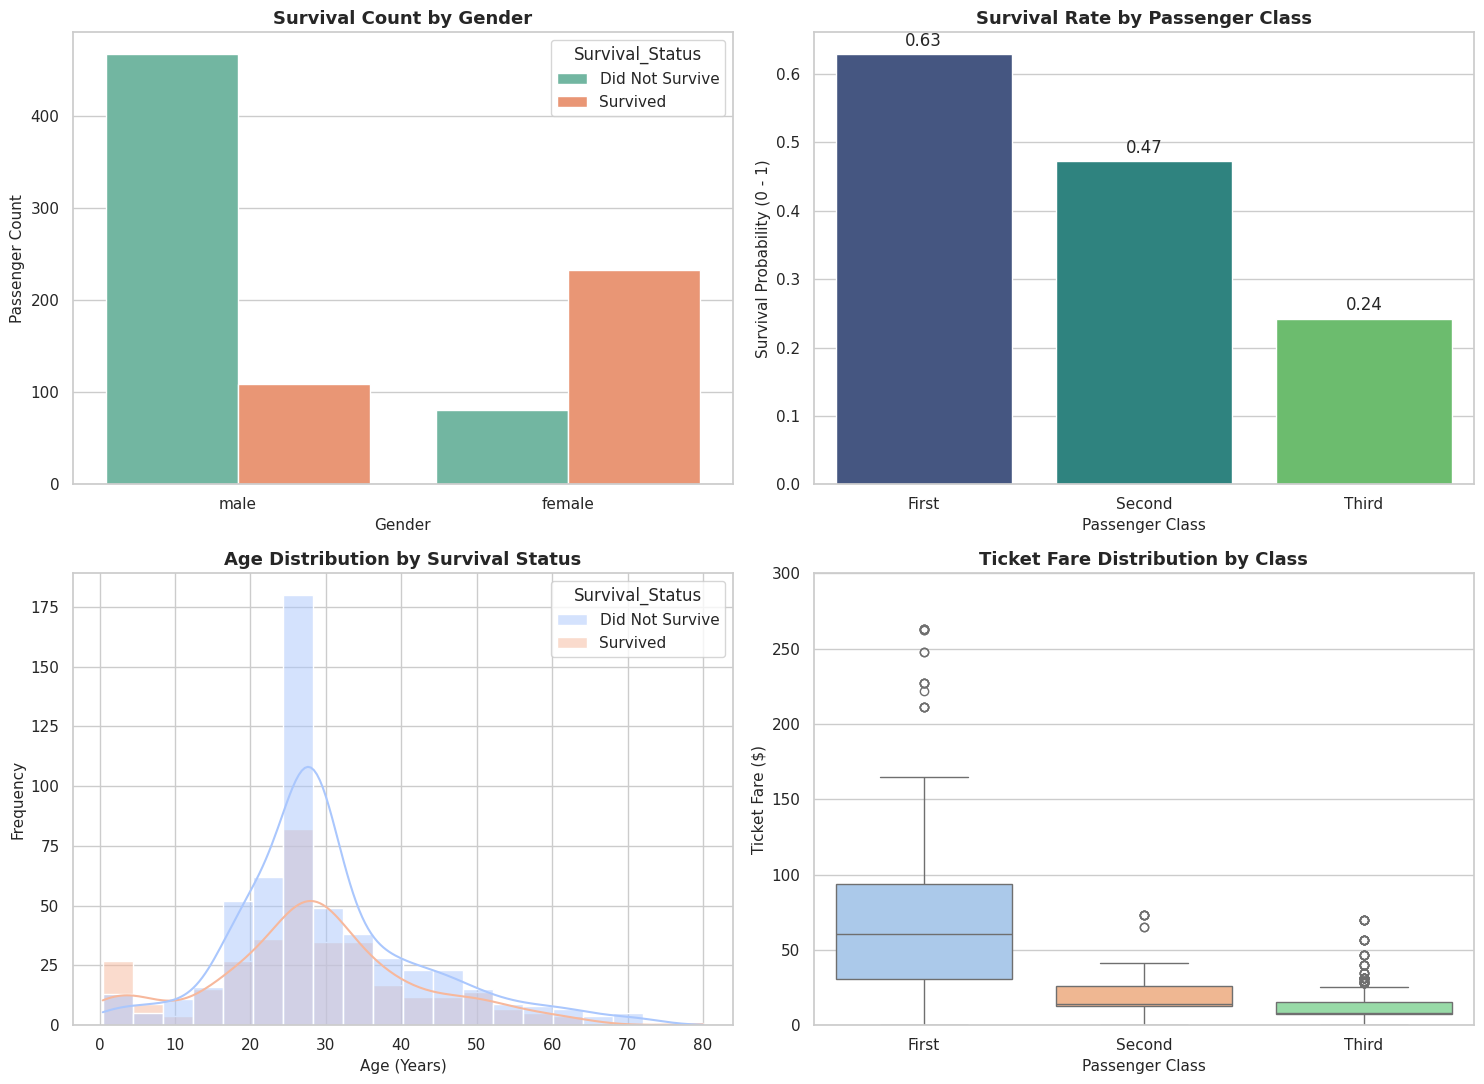

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Dataset load & clean (Self-contained cell)
df_clean = sns.load_dataset("titanic").drop(columns=["deck"])
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])
df_clean["Family_Size"] = df_clean["sibsp"] + df_clean["parch"] + 1
df_clean["Survival_Status"] = df_clean["survived"].map({0: "Did Not Survive", 1: "Survived"})

# 2. Numerical Insights Print කිරීම
print("--- Overall Survival Rate ---")
print(f"Overall Survival Rate: {df_clean['survived'].mean() * 100:.2f}%")

print("\n--- Survival Rate by Gender (%) ---")
print((df_clean.groupby("sex")["survived"].mean() * 100).round(2))

print("\n--- Survival Rate by Passenger Class (%) ---")
print((df_clean.groupby("class", observed=False)["survived"].mean() * 100).round(2))

# 3. 2x2 Visualization Dashboard එක නිර්මාණය කිරීම
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Chart 1: Survival Count by Gender
sns.countplot(data=df_clean, x="sex", hue="Survival_Status", palette="Set2", ax=axes[0, 0])
axes[0, 0].set_title("Survival Count by Gender", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Gender", fontsize=11)
axes[0, 0].set_ylabel("Passenger Count", fontsize=11)

# Chart 2: Survival Rate by Passenger Class
sns.barplot(data=df_clean, x="class", y="survived", hue="class", palette="viridis", legend=False, errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Survival Rate by Passenger Class", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Passenger Class", fontsize=11)
axes[0, 1].set_ylabel("Survival Probability (0 - 1)", fontsize=11)
for container in axes[0, 1].containers:
    axes[0, 1].bar_label(container, fmt="%.2f", padding=3)

# Chart 3: Age Distribution by Survival Status
sns.histplot(data=df_clean, x="age", hue="Survival_Status", bins=20, kde=True, palette="coolwarm", ax=axes[1, 0])
axes[1, 0].set_title("Age Distribution by Survival Status", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Age (Years)", fontsize=11)
axes[1, 0].set_ylabel("Frequency", fontsize=11)

# Chart 4: Ticket Fare Distribution across Classes
sns.boxplot(data=df_clean, x="class", y="fare", hue="class", palette="pastel", legend=False, ax=axes[1, 1])
axes[1, 1].set_ylim(0, 300)  # Extreme outliers නිසා chart එක පැහැදිලිව පෙනීමට limit කිරීම
axes[1, 1].set_title("Ticket Fare Distribution by Class", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Passenger Class", fontsize=11)
axes[1, 1].set_ylabel("Ticket Fare ($)", fontsize=11)

plt.tight_layout()
plt.show()

## Mini Project Summary & Key Findings

### 1. Project Overview
Performed an end-to-end Exploratory Data Analysis (EDA) on the real-world **Titanic Passenger Dataset (891 records)** to uncover demographic and socioeconomic factors influencing passenger survival.

### 2. Data Cleaning & Feature Engineering
* Removed the high-missing `deck` column (over 77% missing values) and imputed missing `age` values using the median (`28.0` years) and `embarked` ports using the mode (`Southampton`), achieving **zero remaining missing values**.
* Engineered new analytical features (`Family_Size`, `Age_Group`, and `Survival_Status`) to enable deeper cohort comparisons.

### 3. Key Analytical Insights
* **Overall Survival Rate:** Only **38.38%** of passengers survived the disaster.
* **Gender Disparity ("Women and Children First"):** Female passengers had a **74.20%** survival rate compared to just **18.89%** for male passengers.
* **Socioeconomic Class Impact:** First-class passengers recorded the highest survival rate at **62.96%**, followed by Second-class (**47.28%**) and Third-class (**24.24%**), demonstrating strong correlation between ticket class and lifeboat access.
* **Age Group Patterns:** Children (`0–12` years) had significantly higher survival rates than young adults and seniors.